In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


df = pd.read_csv("../data/train.csv")
df . head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
0,1,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600
1,2,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400
2,3,CA-2017-138688,12/06/2017,16/06/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200
3,4,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775
4,5,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680


In [8]:
print(df.shape)
df.info()
print(df.isnull().sum())
print("Duplicates:",df.duplicated().sum())

(9800, 18)
<class 'pandas.DataFrame'>
RangeIndex: 9800 entries, 0 to 9799
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9800 non-null   int64  
 1   Order ID       9800 non-null   str    
 2   Order Date     9800 non-null   str    
 3   Ship Date      9800 non-null   str    
 4   Ship Mode      9800 non-null   str    
 5   Customer ID    9800 non-null   str    
 6   Customer Name  9800 non-null   str    
 7   Segment        9800 non-null   str    
 8   Country        9800 non-null   str    
 9   City           9800 non-null   str    
 10  State          9800 non-null   str    
 11  Postal Code    9789 non-null   float64
 12  Region         9800 non-null   str    
 13  Product ID     9800 non-null   str    
 14  Category       9800 non-null   str    
 15  Sub-Category   9800 non-null   str    
 16  Product Name   9800 non-null   str    
 17  Sales          9800 non-null   float64
dtypes: float

In [9]:
# Convert dates (day/month/year format)
df["Order Date"] = pd.to_datetime(df["Order Date"], dayfirst=True)
df["Ship Date"] = pd.to_datetime(df["Ship Date"], dayfirst=True)

# Remove duplicate rows
df = df.drop_duplicates()

# Check which city has the missing postal codes
print(df[df["Postal Code"].isnull()][["City", "State"]].drop_duplicates())

# Add useful columns for analysis
df["Year"] = df["Order Date"].dt.year
df["Month"] = df["Order Date"].dt.month

df.info()

            City    State
2234  Burlington  Vermont
<class 'pandas.DataFrame'>
RangeIndex: 9800 entries, 0 to 9799
Data columns (total 20 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Row ID         9800 non-null   int64         
 1   Order ID       9800 non-null   str           
 2   Order Date     9800 non-null   datetime64[us]
 3   Ship Date      9800 non-null   datetime64[us]
 4   Ship Mode      9800 non-null   str           
 5   Customer ID    9800 non-null   str           
 6   Customer Name  9800 non-null   str           
 7   Segment        9800 non-null   str           
 8   Country        9800 non-null   str           
 9   City           9800 non-null   str           
 10  State          9800 non-null   str           
 11  Postal Code    9789 non-null   float64       
 12  Region         9800 non-null   str           
 13  Product ID     9800 non-null   str           
 14  Category       9800 non-null   

In [10]:
df.loc[df["City"] == "Burlington", "Postal Code"] = 5401
print(df["Postal Code"].isnull().sum())

0


Total Sales: 2261536.78
Category
Technology         827455.8730
Furniture          728658.5757
Office Supplies    705422.3340
Name: Sales, dtype: float64


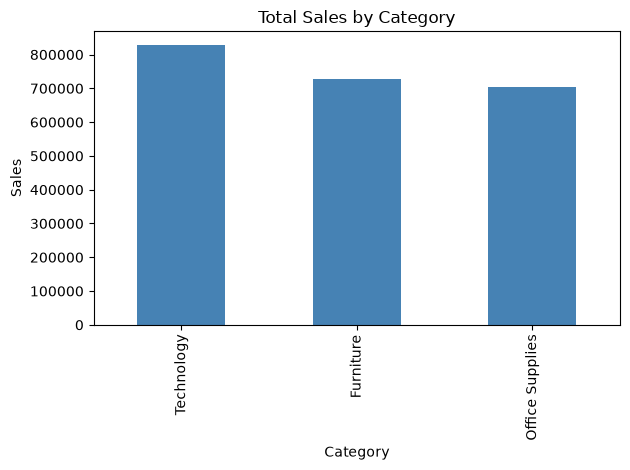

In [11]:
print("Total Sales:", round(df["Sales"].sum(), 2))

sales_by_cat = df.groupby("Category")["Sales"].sum().sort_values(ascending=False)
print(sales_by_cat)

sales_by_cat.plot(kind="bar", color="steelblue")
plt.title("Total Sales by Category")
plt.ylabel("Sales")
plt.tight_layout()
plt.savefig("../images/sales_by_category.png")
plt.show()

Region
West       710219.6845
East       669518.7260
Central    492646.9132
South      389151.4590
Name: Sales, dtype: float64


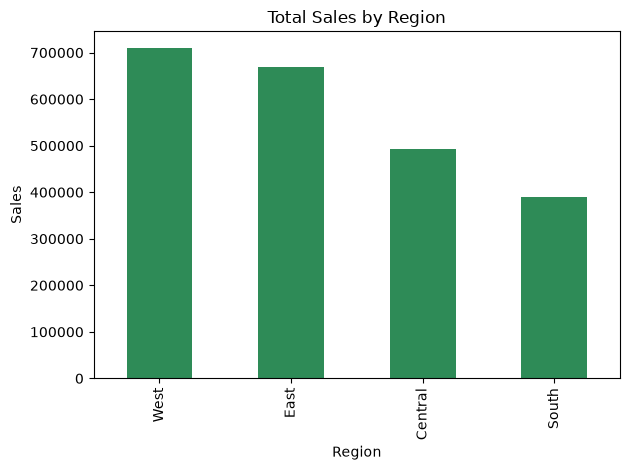

Year
2015    479856.2081
2016    459436.0054
2017    600192.5500
2018    722052.0192
Name: Sales, dtype: float64


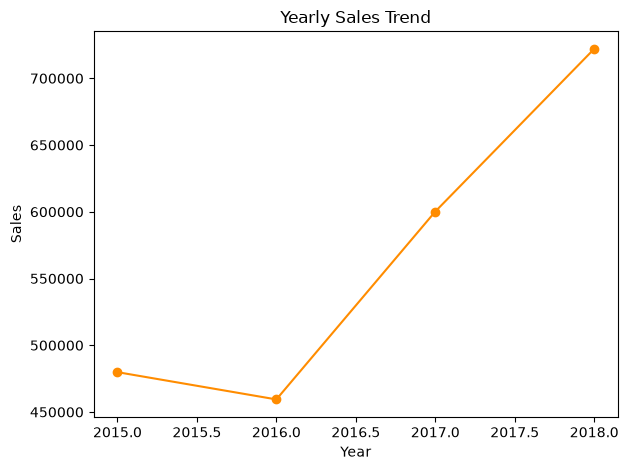

In [12]:
# Sales by region
sales_by_region = df.groupby("Region")["Sales"].sum().sort_values(ascending=False)
print(sales_by_region)

sales_by_region.plot(kind="bar", color="seagreen")
plt.title("Total Sales by Region")
plt.ylabel("Sales")
plt.tight_layout()
plt.savefig("../images/sales_by_region.png")
plt.show()

# Yearly sales trend
yearly = df.groupby("Year")["Sales"].sum()
print(yearly)

yearly.plot(kind="line", marker="o", color="darkorange")
plt.title("Yearly Sales Trend")
plt.ylabel("Sales")
plt.tight_layout()
plt.savefig("../images/yearly_sales.png")
plt.show()

Product Name
Canon imageCLASS 2200 Advanced Copier                                          61599.824
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind    27453.384
Cisco TelePresence System EX90 Videoconferencing Unit                          22638.480
HON 5400 Series Task Chairs for Big and Tall                                   21870.576
GBC DocuBind TL300 Electric Binding System                                     19823.479
GBC Ibimaster 500 Manual ProClick Binding System                               19024.500
Hewlett Packard LaserJet 3310 Copier                                           18839.686
HP Designjet T520 Inkjet Large Format Printer - 24" Color                      18374.895
GBC DocuBind P400 Electric Binding System                                      17965.068
High Speed Automatic Electric Letter Opener                                    17030.312
Name: Sales, dtype: float64


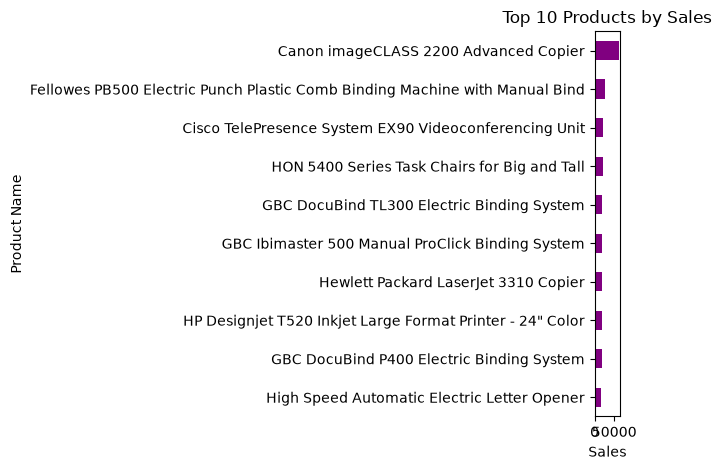

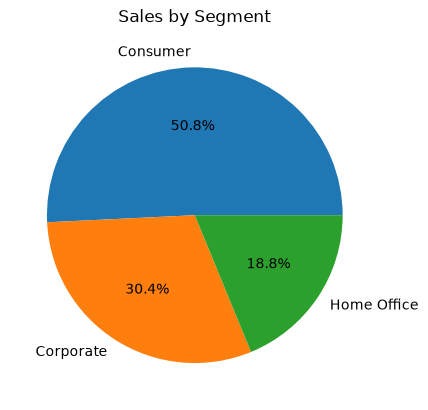

In [13]:
# Top 10 products
top_products = df.groupby("Product Name")["Sales"].sum().sort_values(ascending=False).head(10)
print(top_products)

top_products.sort_values().plot(kind="barh", color="purple")
plt.title("Top 10 Products by Sales")
plt.xlabel("Sales")
plt.tight_layout()
plt.savefig("../images/top_products.png")
plt.show()

# Sales by customer segment
seg = df.groupby("Segment")["Sales"].sum()
seg.plot(kind="pie", autopct="%1.1f%%")
plt.title("Sales by Segment")
plt.ylabel("")
plt.savefig("../images/sales_by_segment.png")
plt.show()

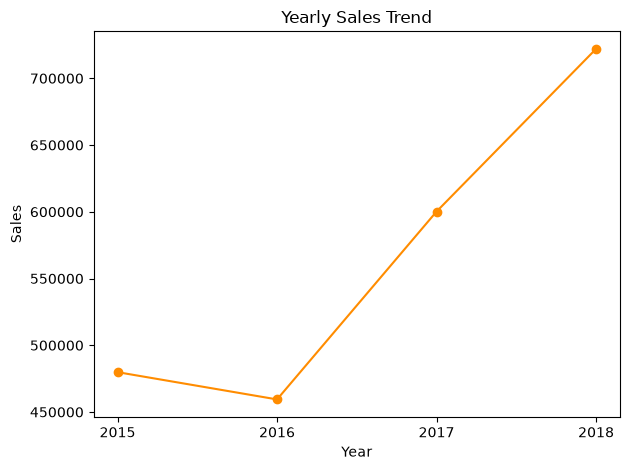

In [14]:
yearly.plot(kind="line", marker="o", color="darkorange")
plt.xticks(yearly.index)
plt.title("Yearly Sales Trend")
plt.ylabel("Sales")
plt.tight_layout()
plt.savefig("../images/yearly_sales.png")
plt.show()